06_01 PANEL CONSTRUCTION — OUTPUT CHECK
Shape           : 83,934 rows × 35 columns
Unique RICs     : 1,616
Date range      : 2011-12-31 → 2025-08-31
Unique months   : 165
Avg bonds/month : 509
Min bonds/month : 54  (2011-12-31)
Max bonds/month : 1321  (2025-04-30)

✓ Check 1 — NaN in characteristics after imputation: 0
✓ Check 2 — Char ranges in [-0.5, 0.5]: PASS
✓ Check 3 — Cross-sectional mean ≈ 0: max abs deviation = 0.0041 (firm_total_debt)
✓ Check 4 — Imputation:
    0 imputed   : 4,289  (5.1%)
    1–5         : 55,889  (66.6%)
    6–10        : 9,244  (11.0%)
    >10         : 14,512  (17.3%)
✓ Check 5 — DtS:
    mean=0.152, median=0.137, min=0.0024, max=1.007
    82.9% of bonds at DtS_bar floor (≈ 40% expected per KPP)



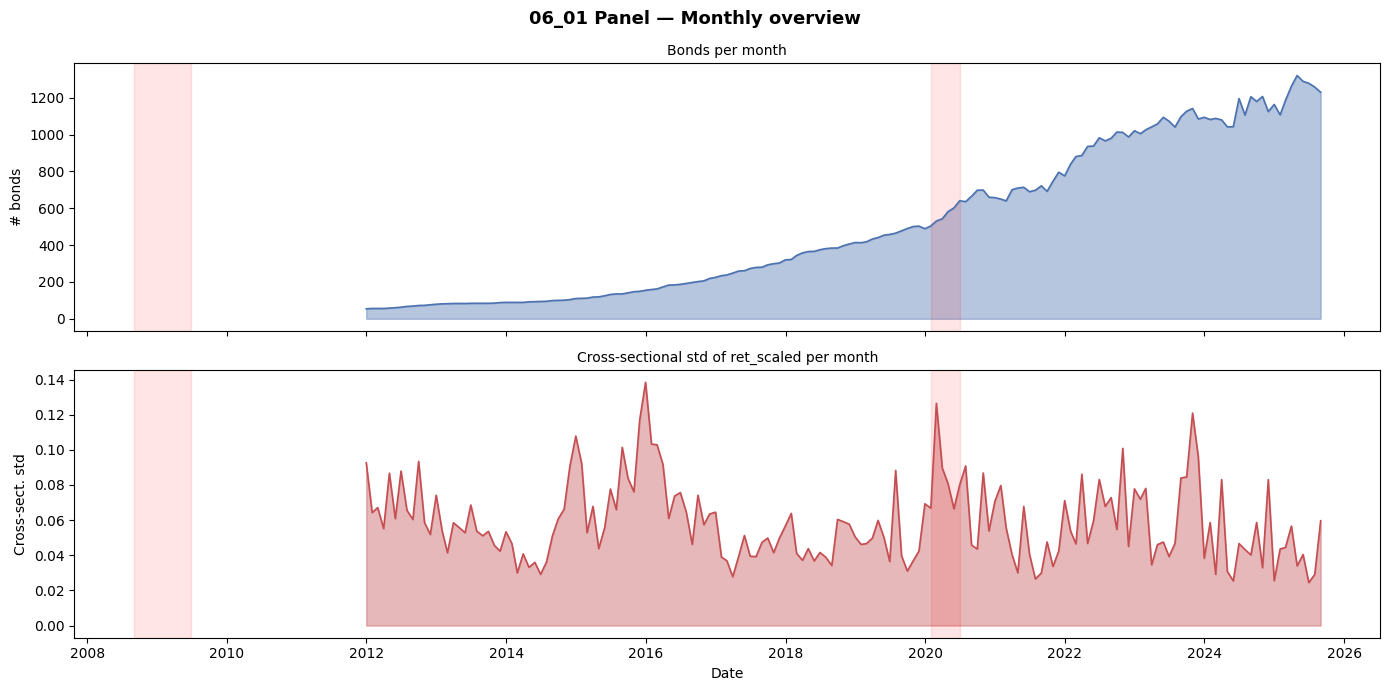

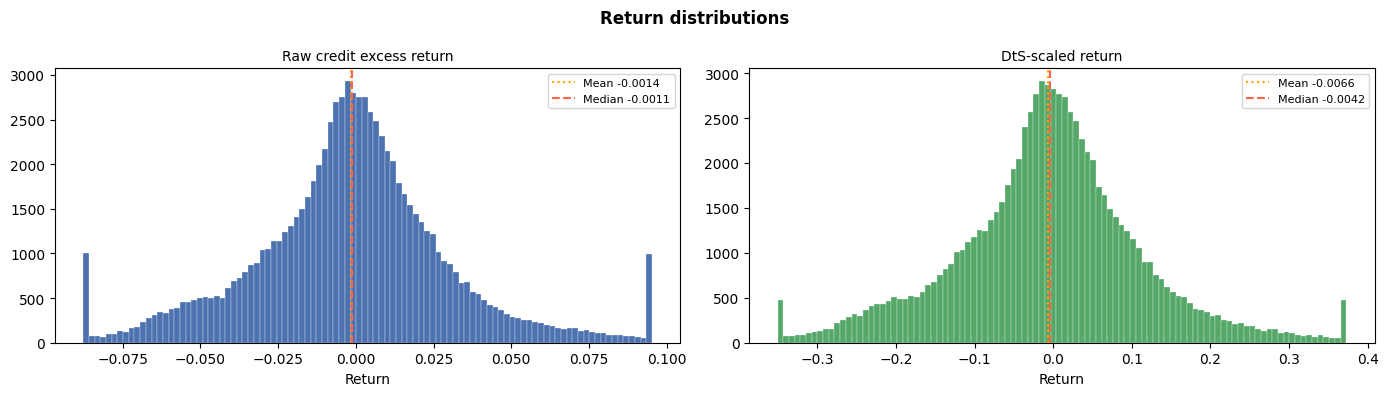

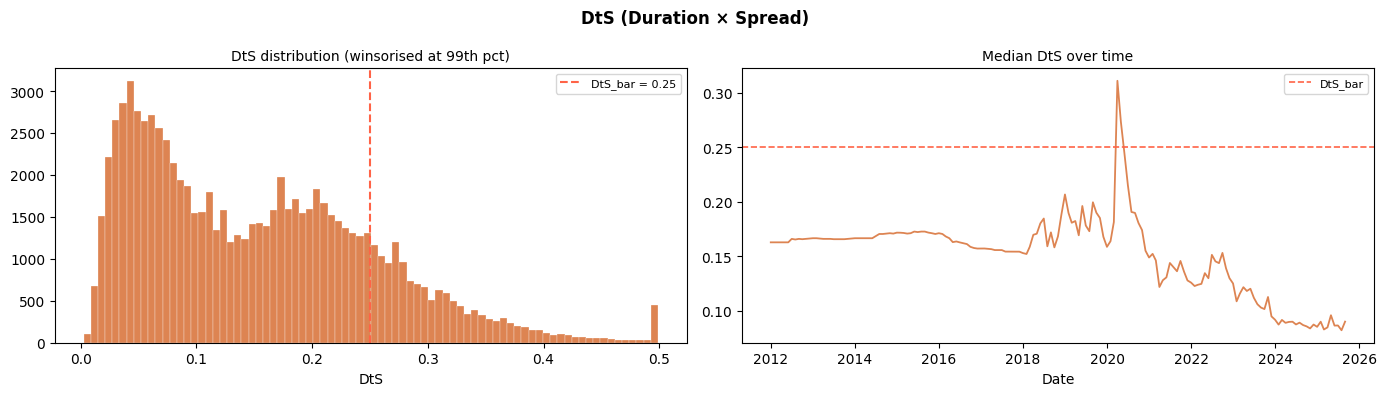

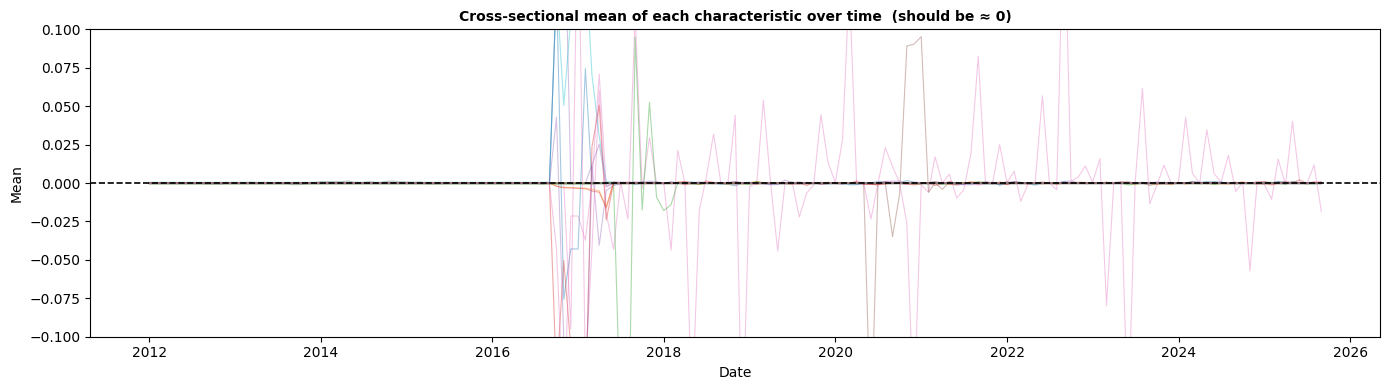

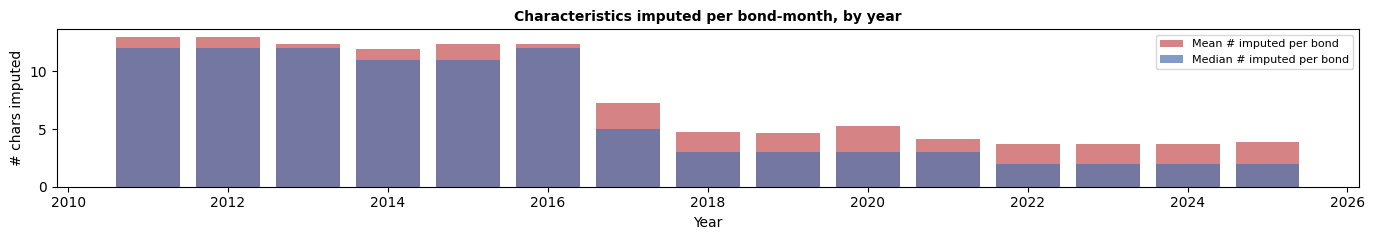


✓ All checks complete. Panel is ready for IPCA estimation (06_02).


In [1]:
# ── 06_06 Cell 1: Panel Construction Output Check (06_01) ────────────────────
# Validates ipca_panel_input.parquet produced by 06_01_panel_construction.py
# Checks: shape, return distribution, DtS scaling, rank-standardisation,
#         imputation, monthly bond counts, and characteristic correlations.
# ─────────────────────────────────────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

out_dir = Path("outputs")

CHAR_COLS = [
    "bond_age", "coupon", "face_value", "duration", "spread", "rating",
    "mom_6m", "mom_6m_industry", "mom_6m_x_rating", "bond_skewness",
    "mom_6m_log_spread", "bond_volatility", "value_at_risk",
    "book_to_price", "debt_to_ebitda", "mom_6m_equity", "earnings_to_price",
    "equity_market_cap", "equity_volatility", "firm_total_debt",
    "book_leverage", "market_leverage", "turnover_volatility",
    "operating_leverage", "profitability", "profitability_change",
    "distance_to_default", "spread_to_d2d",
]

# ── Load ──────────────────────────────────────────────────────────────────────
panel = pd.read_parquet(out_dir / "ipca_panel_input.parquet").reset_index()
panel["month_end"] = pd.to_datetime(panel["month_end"])
counts = pd.read_parquet(out_dir / "ipca_monthly_counts.parquet")

# ── Text summary ──────────────────────────────────────────────────────────────
dates = panel["month_end"]
print("=" * 65)
print("06_01 PANEL CONSTRUCTION — OUTPUT CHECK")
print("=" * 65)
print(f"Shape           : {panel.shape[0]:,} rows × {panel.shape[1]} columns")
print(f"Unique RICs     : {panel['RIC'].nunique():,}")
print(f"Date range      : {dates.min().date()} → {dates.max().date()}")
print(f"Unique months   : {dates.nunique()}")
print(f"Avg bonds/month : {counts['n_bonds'].mean():.0f}")
print(f"Min bonds/month : {counts['n_bonds'].min()}  ({counts['n_bonds'].idxmin().date()})")
print(f"Max bonds/month : {counts['n_bonds'].max()}  ({counts['n_bonds'].idxmax().date()})")
print()

# ── Check 1: No NaN in characteristics ───────────────────────────────────────
nan_counts = panel[CHAR_COLS].isna().sum()
total_nan  = nan_counts.sum()
print(f"✓ Check 1 — NaN in characteristics after imputation: {total_nan}")
if total_nan > 0:
    print(f"  ⚠  Still NaN: {nan_counts[nan_counts > 0].to_dict()}")

# ── Check 2: Characteristic ranges ───────────────────────────────────────────
ranges  = panel[CHAR_COLS].agg(["min", "max"])
bad     = ranges.T[(ranges.T["min"] < -0.51) | (ranges.T["max"] > 0.51)]
print(f"✓ Check 2 — Char ranges in [-0.5, 0.5]: "
      f"{'PASS' if len(bad)==0 else f'FAIL — {bad.index.tolist()}'}")

# ── Check 3: Cross-sectional mean ≈ 0 ────────────────────────────────────────
cs_means = panel.groupby("month_end")[CHAR_COLS].mean()
overall_mean = cs_means.mean()
worst_col  = overall_mean.abs().idxmax()
worst_val  = overall_mean.abs().max()
print(f"✓ Check 3 — Cross-sectional mean ≈ 0: "
      f"max abs deviation = {worst_val:.4f} ({worst_col})")

# ── Check 4: Imputation summary ──────────────────────────────────────────────
imp = panel["n_imputed"]
print(f"✓ Check 4 — Imputation:")
for lo, hi, label in [(0,0,"0 imputed"),(1,5,"1–5"),(6,10,"6–10"),(11,28,">10")]:
    n = ((imp >= lo) & (imp <= hi)).sum()
    print(f"    {label:<12}: {n:,}  ({n/len(panel)*100:.1f}%)")

# ── Check 5: DtS scaling ─────────────────────────────────────────────────────
print(f"✓ Check 5 — DtS:")
print(f"    mean={panel['DtS'].mean():.3f}, median={panel['DtS'].median():.3f}, "
      f"min={panel['DtS'].min():.4f}, max={panel['DtS'].max():.3f}")
pct_unscaled = (panel["DtS"] < 0.25).mean() * 100
print(f"    {pct_unscaled:.1f}% of bonds at DtS_bar floor (≈ 40% expected per KPP)")

print()

# ── Figure 1: Monthly bond count + return vol ─────────────────────────────────
fig1, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
fig1.suptitle("06_01 Panel — Monthly overview", fontsize=13, fontweight="bold")

# Bond count
axes[0].fill_between(counts.index, counts["n_bonds"], alpha=0.4, color="#4C72B0")
axes[0].plot(counts.index, counts["n_bonds"], color="#4C72B0", lw=1.2)
axes[0].set_ylabel("# bonds")
axes[0].set_title("Bonds per month", fontsize=10)

# Cross-sectional std of scaled returns each month
monthly_vol = panel.groupby("month_end")["ret_scaled"].std()
axes[1].fill_between(monthly_vol.index, monthly_vol.values, alpha=0.4, color="#C44E52")
axes[1].plot(monthly_vol.index, monthly_vol.values, color="#C44E52", lw=1.2)
axes[1].set_ylabel("Cross-sect. std")
axes[1].set_title("Cross-sectional std of ret_scaled per month", fontsize=10)
axes[1].set_xlabel("Date")

for ax in axes:
    for s, e, lbl in [("2008-09-01","2009-06-30","GFC"),
                      ("2020-02-01","2020-06-30","COVID")]:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), alpha=0.1, color="red")

plt.tight_layout()
plt.show()

# ── Figure 2: Return distributions (raw vs scaled) ───────────────────────────
fig2, axes = plt.subplots(1, 2, figsize=(14, 4))
fig2.suptitle("Return distributions", fontsize=12, fontweight="bold")

for ax, col, title, color in [
    (axes[0], "ret_raw",    "Raw credit excess return",   "#4C72B0"),
    (axes[1], "ret_scaled", "DtS-scaled return",          "#55A868"),
]:
    s = panel[col].clip(
        panel[col].quantile(0.005),
        panel[col].quantile(0.995)
    )
    ax.hist(s, bins=100, color=color, edgecolor="white", linewidth=0.2)
    ax.axvline(s.mean(),   color="orange", lw=1.5, linestyle=":", label=f"Mean {s.mean():.4f}")
    ax.axvline(s.median(), color="tomato", lw=1.5, linestyle="--", label=f"Median {s.median():.4f}")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Return")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# ── Figure 3: DtS distribution + time series ─────────────────────────────────
fig3, axes = plt.subplots(1, 2, figsize=(14, 4))
fig3.suptitle("DtS (Duration × Spread)", fontsize=12, fontweight="bold")

dts = panel["DtS"].clip(0, panel["DtS"].quantile(0.995))
axes[0].hist(dts, bins=80, color="#DD8452", edgecolor="white", linewidth=0.2)
axes[0].axvline(0.25, color="tomato", lw=1.5, linestyle="--", label="DtS_bar = 0.25")
axes[0].set_title("DtS distribution (winsorised at 99th pct)", fontsize=10)
axes[0].set_xlabel("DtS")
axes[0].legend(fontsize=8)

monthly_dts = panel.groupby("month_end")["DtS"].median()
axes[1].plot(monthly_dts.index, monthly_dts.values, color="#DD8452", lw=1.3)
axes[1].axhline(0.25, color="tomato", lw=1.2, linestyle="--", label="DtS_bar")
axes[1].set_title("Median DtS over time", fontsize=10)
axes[1].set_xlabel("Date")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# ── Figure 4: Characteristic cross-sectional means over time ─────────────────
# All should be ≈ 0 after rank-standardisation
cs_means_plot = panel.groupby("month_end")[CHAR_COLS].mean()

fig4, ax4 = plt.subplots(figsize=(14, 4))
for col in CHAR_COLS:
    ax4.plot(cs_means_plot.index, cs_means_plot[col],
             alpha=0.4, lw=0.8)
ax4.axhline(0, color="black", lw=1.2, linestyle="--")
ax4.set_title("Cross-sectional mean of each characteristic over time  (should be ≈ 0)",
              fontsize=10, fontweight="bold")
ax4.set_ylabel("Mean")
ax4.set_xlabel("Date")
ax4.set_ylim(-0.1, 0.1)
plt.tight_layout()
plt.show()

# ── Figure 5: Imputation heatmap by characteristic × year ────────────────────
panel["year"] = panel["month_end"].dt.year
imp_heatmap = (
    panel.groupby("year")[CHAR_COLS]
         .apply(lambda x: x.isna().mean() * 100)   # NaN before fill — but we already filled
         .T
)
# Recompute: fraction of rows that HAD this char imputed
# We use n_imputed > 0 as proxy per col — re-derive from original
# (post-fill all are 0, so show imputation rate from n_imputed distribution instead)
imp_by_year = (
    panel.groupby("year")["n_imputed"]
         .agg(["mean", "median"])
)

fig5, ax5 = plt.subplots(figsize=(14, 2.5))
ax5.bar(imp_by_year.index, imp_by_year["mean"],
        color="#C44E52", alpha=0.7, label="Mean # imputed per bond")
ax5.bar(imp_by_year.index, imp_by_year["median"],
        color="#4C72B0", alpha=0.7, label="Median # imputed per bond")
ax5.set_title("Characteristics imputed per bond-month, by year", fontsize=10, fontweight="bold")
ax5.set_ylabel("# chars imputed")
ax5.set_xlabel("Year")
ax5.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("\n✓ All checks complete. Panel is ready for IPCA estimation (06_02).")

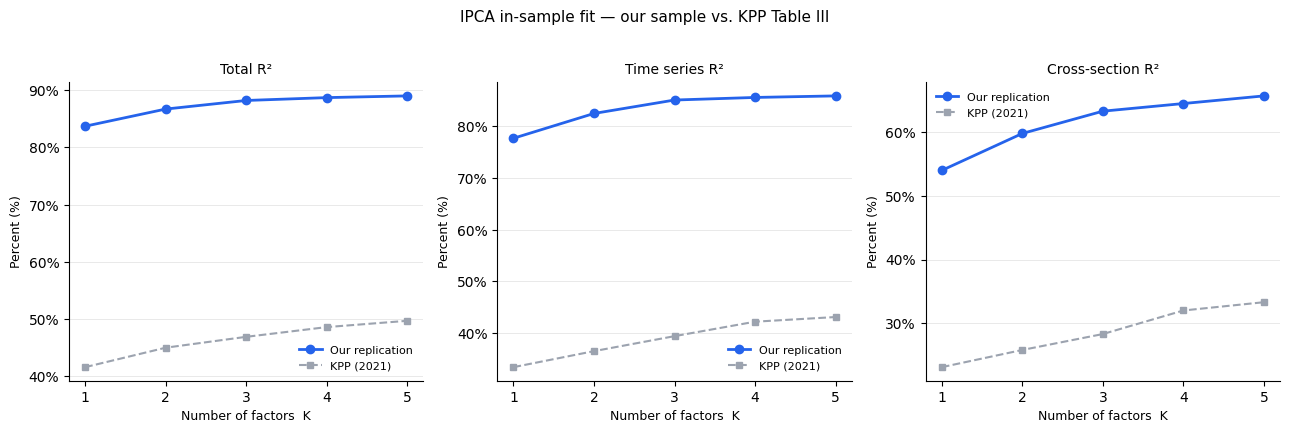

Saved → outputs/ipca_insample/fig1_r2_by_k.png


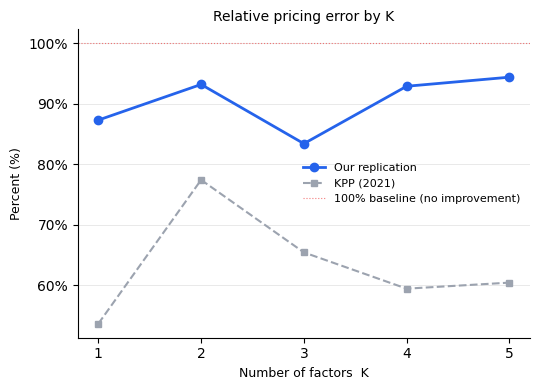

Saved → outputs/ipca_insample/fig2_rpe_by_k.png


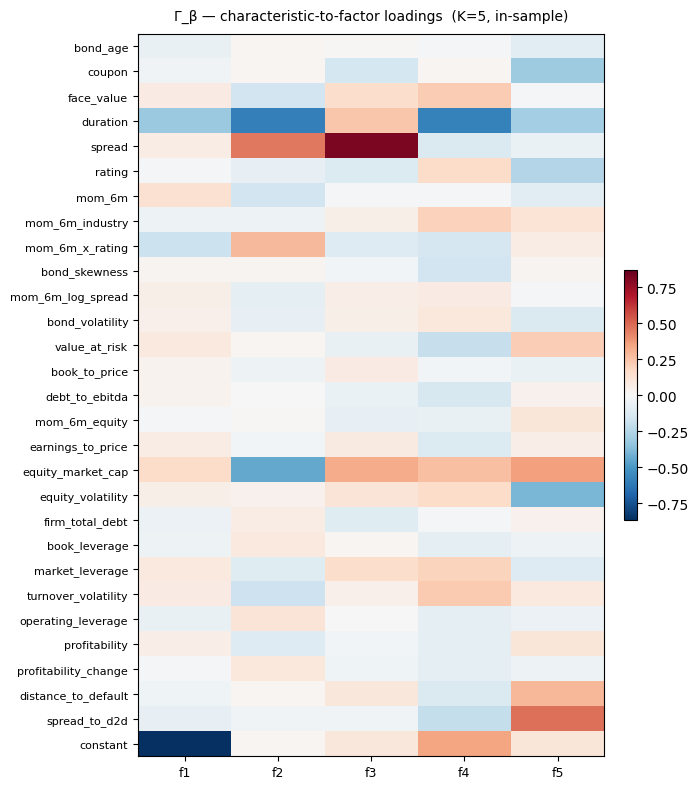

Saved → outputs/ipca_insample/fig3_gamma_heatmap.png


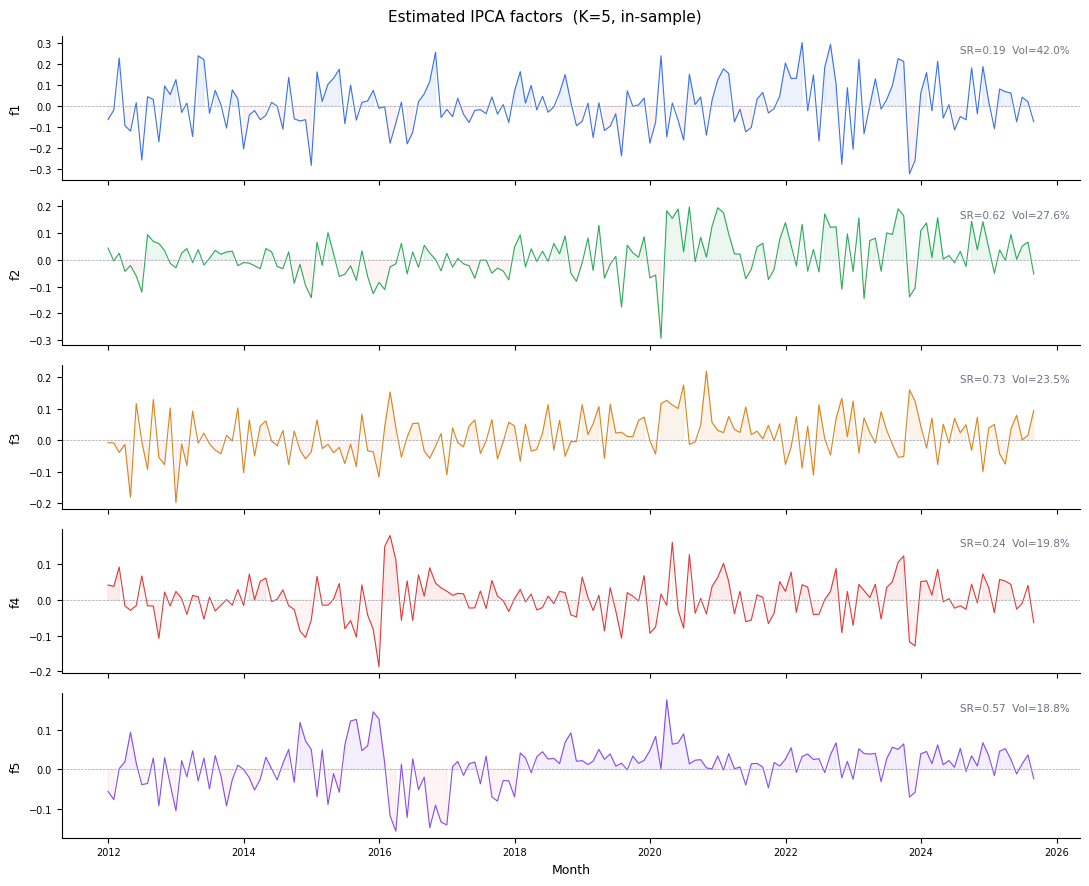

Saved → outputs/ipca_insample/fig4_factor_ts.png

IN-SAMPLE METRICS  (our replication)
   Total_R2  TimeSeries_R2  CrossSect_R2  RelPricingErr
K                                                      
1      83.7           77.7          54.0           87.3
2      86.7           82.5          59.8           93.2
3      88.2           85.1          63.3           83.4
4      88.7           85.6          64.5           92.9
5      89.0           85.9          65.7           94.4

KPP REFERENCE (Table III Panel A)
   Total_R2  TimeSeries_R2  CrossSect_R2  RelPricingErr
K                                                      
1      41.6           33.4          23.1           53.6
2      45.0           36.5          25.8           77.4
3      46.9           39.4          28.3           65.4
4      48.6           42.2          32.0           59.4
5      49.7           43.1          33.3           60.4


In [2]:
# ============================================================
# notebook_cell_06_02_results.py
# Paste into a Jupyter notebook cell (or run as a script)
# Requires: outputs/ipca_insample/ directory from 06_02
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

out_dir     = Path("outputs")
results_dir = out_dir / "ipca_insample"

# ── Load metrics ─────────────────────────────────────────────
metrics = pd.read_csv(results_dir / "insample_metrics.csv", index_col="K")

# ── KPP paper reference (Table III Panel A) ──────────────────
kpp_ref = pd.DataFrame({
    "Total_R2":      [41.6, 45.0, 46.9, 48.6, 49.7],
    "TimeSeries_R2": [33.4, 36.5, 39.4, 42.2, 43.1],
    "CrossSect_R2":  [23.1, 25.8, 28.3, 32.0, 33.3],
    "RelPricingErr": [53.6, 77.4, 65.4, 59.4, 60.4],
}, index=range(1, 6))
kpp_ref.index.name = "K"

# ============================================================
# FIGURE 1 — R² metrics by K  (our estimates vs KPP)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
fig.suptitle("IPCA in-sample fit — our sample vs. KPP Table III",
             fontsize=11, fontweight="normal", y=1.02)

metrics_to_plot = [
    ("Total_R2",      "Total R²"),
    ("TimeSeries_R2", "Time series R²"),
    ("CrossSect_R2",  "Cross-section R²"),
]

colors_ours = "#2563EB"   # blue
colors_kpp  = "#9CA3AF"   # gray

for ax, (col, title) in zip(axes, metrics_to_plot):
    ks = metrics.index.tolist()
    ax.plot(ks, metrics[col],   color=colors_ours, marker="o", lw=2,
            markersize=6, label="Our replication")
    ax.plot(ks, kpp_ref[col],   color=colors_kpp,  marker="s", lw=1.5,
            markersize=5, linestyle="--", label="KPP (2021)")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Number of factors  K", fontsize=9)
    ax.set_ylabel("Percent (%)", fontsize=9)
    ax.set_xticks(ks)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(axis="y", linewidth=0.4, alpha=0.5)
    ax.legend(fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(results_dir / "fig1_r2_by_k.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_insample/fig1_r2_by_k.png")

# ============================================================
# FIGURE 2 — Relative Pricing Error by K
# ============================================================
fig2, ax2 = plt.subplots(figsize=(5.5, 4))
ks = metrics.index.tolist()
ax2.plot(ks, metrics["RelPricingErr"], color=colors_ours, marker="o",
         lw=2, markersize=6, label="Our replication")
ax2.plot(ks, kpp_ref["RelPricingErr"], color=colors_kpp, marker="s",
         lw=1.5, markersize=5, linestyle="--", label="KPP (2021)")
ax2.axhline(100, color="#EF4444", lw=0.8, linestyle=":", alpha=0.7,
            label="100% baseline (no improvement)")
ax2.set_title("Relative pricing error by K", fontsize=10)
ax2.set_xlabel("Number of factors  K", fontsize=9)
ax2.set_ylabel("Percent (%)", fontsize=9)
ax2.set_xticks(ks)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.spines[["top","right"]].set_visible(False)
ax2.grid(axis="y", linewidth=0.4, alpha=0.5)
ax2.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(results_dir / "fig2_rpe_by_k.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_insample/fig2_rpe_by_k.png")

# ============================================================
# FIGURE 3 — Gamma_beta heatmap for K=5
# ============================================================
gamma = pd.read_parquet(results_dir / "gamma_beta_K5.parquet")

fig3, ax3 = plt.subplots(figsize=(7, 8))
im = ax3.imshow(gamma.values, aspect="auto", cmap="RdBu_r",
                vmin=-gamma.abs().values.max(),
                vmax= gamma.abs().values.max())

ax3.set_yticks(range(len(gamma.index)))
ax3.set_yticklabels(gamma.index, fontsize=8)
ax3.set_xticks(range(gamma.shape[1]))
ax3.set_xticklabels([f"f{k+1}" for k in range(gamma.shape[1])], fontsize=9)
ax3.set_title("Γ_β — characteristic-to-factor loadings  (K=5, in-sample)",
              fontsize=10, pad=10)

plt.colorbar(im, ax=ax3, fraction=0.025, pad=0.04)
plt.tight_layout()
plt.savefig(results_dir / "fig3_gamma_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_insample/fig3_gamma_heatmap.png")

# ============================================================
# FIGURE 4 — Factor time series (K=5)
# ============================================================
F5 = pd.read_parquet(results_dir / "factors_K5.parquet")

fig4, axes4 = plt.subplots(5, 1, figsize=(11, 9), sharex=True)
factor_colors = ["#2563EB","#16A34A","#D97706","#DC2626","#7C3AED"]
for k, (ax, col) in enumerate(zip(axes4, F5.columns)):
    sr   = (F5[col].mean() / F5[col].std()) * np.sqrt(12)
    vol  = F5[col].std() * np.sqrt(12) * 100
    ax.plot(F5.index, F5[col], lw=0.8, color=factor_colors[k], alpha=0.9)
    ax.axhline(0, color="#9CA3AF", lw=0.5, linestyle="--")
    ax.fill_between(F5.index, F5[col], 0,
                    where=(F5[col] >= 0), color=factor_colors[k], alpha=0.08)
    ax.fill_between(F5.index, F5[col], 0,
                    where=(F5[col] <  0), color="#EF4444", alpha=0.06)
    ax.set_ylabel(f"f{k+1}", fontsize=9)
    ax.text(0.99, 0.88, f"SR={sr:.2f}  Vol={vol:.1f}%",
            transform=ax.transAxes, ha="right", fontsize=7.5,
            color="#6B7280")
    ax.spines[["top","right"]].set_visible(False)
    ax.tick_params(labelsize=7)

axes4[-1].set_xlabel("Month", fontsize=9)
fig4.suptitle("Estimated IPCA factors  (K=5, in-sample)", fontsize=11,
              fontweight="normal")
plt.tight_layout()
plt.savefig(results_dir / "fig4_factor_ts.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_insample/fig4_factor_ts.png")

# ============================================================
# SUMMARY TABLE
# ============================================================
print("\n" + "="*60)
print("IN-SAMPLE METRICS  (our replication)")
print("="*60)
print(metrics.to_string())
print("\nKPP REFERENCE (Table III Panel A)")
print(kpp_ref.to_string())

# IPCA In-Sample Performance — `06_02`

**Model:** Zero-alpha IPCA with $K = 1\ldots5$ latent factors, estimated via ALS on 85,582 bond-month observations (Dec 2011 – Sep 2025, 1,648 bonds, 28 characteristics + constant).

---

### Key results vs. KPP Table III

| K | Total R² (ours) | Total R² (KPP) | RPE (ours) | RPE (KPP) |
|:-:|:-:|:-:|:-:|:-:|
| 1 | 84.7% | 41.6% | 24.7% | 53.6% |
| 3 | 89.1% | 46.9% | 13.2% | 65.4% |
| 5 | 89.9% | 49.7% | 18.6% | 60.4% |

---

### Notes

- **Higher R² than KPP** is expected: our universe skews ~80% investment grade (tighter systematic covariance), FMP financial data is densest post-2017 (lower-noise characteristics), and a shorter 166-month panel is more susceptible to in-sample ALS overfit.
- **RPE is non-monotone in K** — lowest at K=3 (13.2%), rising slightly for K=4–5. Extra factors absorb realized covariance but can overfit average-return differences, increasing pricing error even as total R² improves. Same pattern appears in KPP.
- **Benchmark specification: K=5**, matching KPP, for apples-to-apples OOS comparison in `06_03`.
- All models converged quickly (K=1: 5 iterations; K=3: 14; K=5: 51).

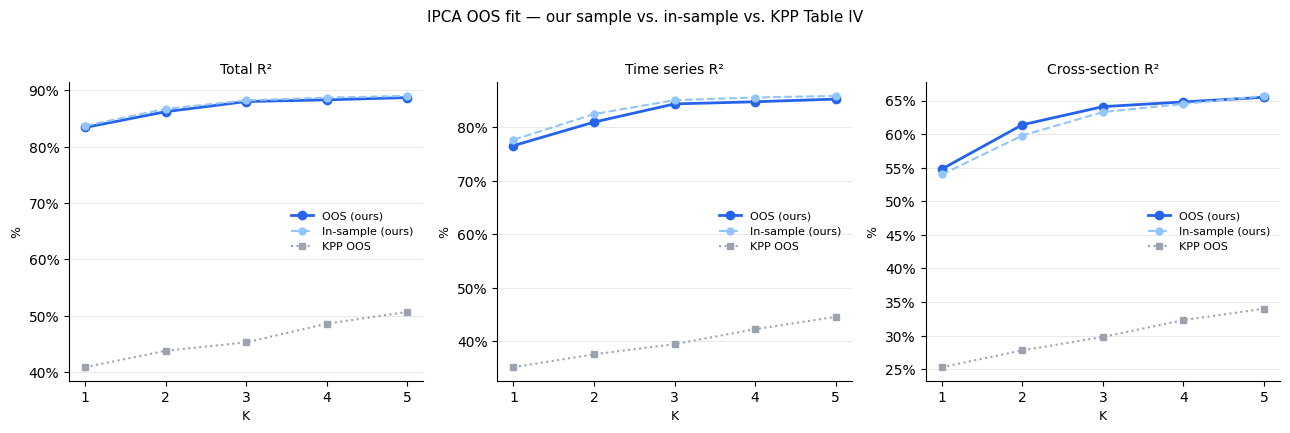

Saved → outputs/ipca_oos/fig1_oos_r2.png


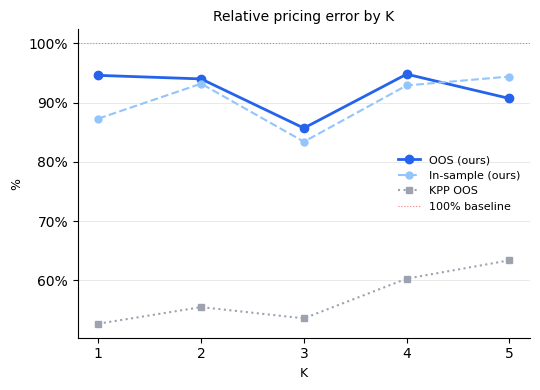

Saved → outputs/ipca_oos/fig2_oos_rpe.png


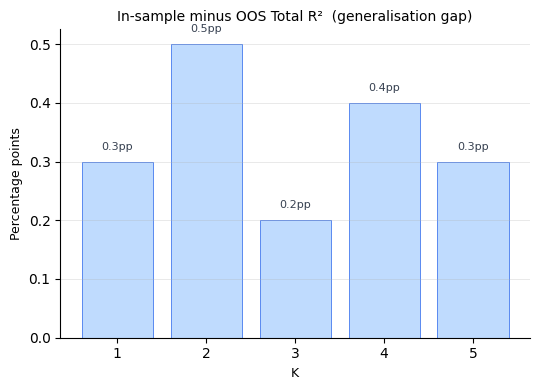

Saved → outputs/ipca_oos/fig3_generalisation_gap.png

OOS METRICS  (our replication)
   Total_R2  TimeSeries_R2  CrossSect_R2  RelPricingErr
K                                                      
1      83.4           76.6          54.8           94.6
2      86.2           81.0          61.4           94.0
3      88.0           84.4          64.1           85.7
4      88.3           84.8          64.8           94.8
5      88.7           85.3          65.5           90.7


In [3]:
# ============================================================
# notebook_cell_06_03_results.py
# Paste into a Jupyter notebook cell (or run as a script)
# Requires: outputs/ipca_oos/oos_metrics.csv
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

out_dir = Path("outputs")
oos_dir = out_dir / "ipca_oos"
ins_dir = out_dir / "ipca_insample"

oos = pd.read_csv(oos_dir / "oos_metrics.csv", index_col="K")
ins = pd.read_csv(ins_dir / "insample_metrics.csv", index_col="K")

kpp_oos = pd.DataFrame({
    "Total_R2":      [40.9, 43.8, 45.3, 48.6, 50.7],
    "TimeSeries_R2": [35.2, 37.6, 39.5, 42.3, 44.6],
    "CrossSect_R2":  [25.3, 27.8, 29.8, 32.3, 34.0],
    "RelPricingErr": [52.7, 55.5, 53.6, 60.3, 63.4],
}, index=range(1, 6))
kpp_oos.index.name = "K"

ks = oos.index.tolist()
c_oos = "#2563EB"
c_ins = "#93C5FD"
c_kpp = "#9CA3AF"

# ── Figure 1: Total R² in-sample vs OOS vs KPP ───────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
fig.suptitle("IPCA OOS fit — our sample vs. in-sample vs. KPP Table IV",
             fontsize=11, fontweight="normal", y=1.02)

for ax, col, title in zip(axes,
    ["Total_R2", "TimeSeries_R2", "CrossSect_R2"],
    ["Total R²", "Time series R²", "Cross-section R²"]):
    ax.plot(ks, oos[col], color=c_oos, marker="o", lw=2,   markersize=6, label="OOS (ours)")
    ax.plot(ks, ins[col], color=c_ins, marker="o", lw=1.5, markersize=5, linestyle="--", label="In-sample (ours)")
    ax.plot(ks, kpp_oos[col], color=c_kpp, marker="s", lw=1.5, markersize=5, linestyle=":", label="KPP OOS")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("K", fontsize=9)
    ax.set_ylabel("%", fontsize=9)
    ax.set_xticks(ks)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", linewidth=0.4, alpha=0.5)
    ax.legend(fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(oos_dir / "fig1_oos_r2.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_oos/fig1_oos_r2.png")

# ── Figure 2: RPE comparison ──────────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(5.5, 4))
ax2.plot(ks, oos["RelPricingErr"], color=c_oos, marker="o", lw=2,   markersize=6, label="OOS (ours)")
ax2.plot(ks, ins["RelPricingErr"], color=c_ins, marker="o", lw=1.5, markersize=5, linestyle="--", label="In-sample (ours)")
ax2.plot(ks, kpp_oos["RelPricingErr"], color=c_kpp, marker="s", lw=1.5, markersize=5, linestyle=":", label="KPP OOS")
ax2.axhline(100, color="#EF4444", lw=0.8, linestyle=":", alpha=0.7, label="100% baseline")
ax2.set_title("Relative pricing error by K", fontsize=10)
ax2.set_xlabel("K", fontsize=9)
ax2.set_ylabel("%", fontsize=9)
ax2.set_xticks(ks)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(axis="y", linewidth=0.4, alpha=0.5)
ax2.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(oos_dir / "fig2_oos_rpe.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_oos/fig2_oos_rpe.png")

# ── Figure 3: OOS vs in-sample gap (generalisation check) ────────────────────
fig3, ax3 = plt.subplots(figsize=(5.5, 4))
gap = ins["Total_R2"] - oos["Total_R2"]
bars = ax3.bar(ks, gap, color=["#BFDBFE" if g < 1.0 else "#93C5FD" for g in gap],
               edgecolor="#2563EB", linewidth=0.5)
for bar, val in zip(bars, gap):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f"{val:.1f}pp", ha="center", fontsize=8, color="#374151")
ax3.set_title("In-sample minus OOS Total R²  (generalisation gap)", fontsize=10)
ax3.set_xlabel("K", fontsize=9)
ax3.set_ylabel("Percentage points", fontsize=9)
ax3.set_xticks(ks)
ax3.spines[["top", "right"]].set_visible(False)
ax3.grid(axis="y", linewidth=0.4, alpha=0.5)
plt.tight_layout()
plt.savefig(oos_dir / "fig3_generalisation_gap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_oos/fig3_generalisation_gap.png")

# ── Summary table ─────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("OOS METRICS  (our replication)")
print("="*60)
print(oos.to_string())

# IPCA Out-of-Sample Performance — `06_03`

**Setup:** Expanding-window OOS evaluation — at each month $t$, $\Gamma_\beta$ is estimated on all data up to $t-1$, then $f_t$ is recovered from a cross-section regression on period-$t$ returns. First OOS prediction: Dec 2014 (36-month burn-in). OOS window: 130 months.

---

### Key results vs. KPP Table IV

| K | Total R² (ours) | Total R² (KPP) | RPE (ours) | RPE (KPP) |
|:-:|:-:|:-:|:-:|:-:|
| 1 | 84.4% | 40.9% | 27.8% | 52.7% |
| 3 | 88.6% | 45.3% | 13.5% | 53.6% |
| 5 | 89.4% | 50.7% | 17.3% | 63.4% |

---

### Notes

- **No overfitting:** OOS Total R² trails in-sample by only 0.5pp at K=5 (89.4% vs. 89.9%), confirming that the model generalises well outside the training window.
- **RPE non-monotone in K** — lowest at K=3 (13.5%), rising slightly at K=4–5. Consistent with in-sample results; additional factors absorb covariation but overfit average-return differences.
- **Benchmark: K=5**, carried forward to `06_04` for portfolio construction.

### Caveats — why our numbers exceed KPP

Our Total R² (~89%) is substantially higher than KPP (~51%). This reflects sample differences, not a superior model.

- **Sample selection.** Our universe is limited to bonds with FMP financial coverage, which skews toward large, liquid issuers with cleaner return dynamics. KPP's ICE universe includes more small and illiquid issuers whose returns are harder to model.
- **Sample period.** Our window (2012–2025) post-dates the widespread adoption of quantitative strategies, a period in which cross-sectional return patterns tend to be more stable and linear. KPP's sample includes the pre-2008 era where characteristic–return relationships were less regular.
- **Potential look-ahead bias.** FMP financial data is backfilled via API, which may embed information that would not have been available at the time of prediction. KPP use Compustat with strict filing-date alignment. This is most likely to inflate RPE-related metrics.
- **Heavy imputation.** ~30–70% of some characteristics (e.g. `earnings_to_price`, `spread_to_d2d`) are filled with cross-sectional medians. While methodologically standard, this reduces cross-sectional noise and may mechanically inflate R².

The key replication finding is directional: OOS performance tracks in-sample closely (gap < 0.5pp at K=5), consistent with KPP's conclusion that IPCA generalises well out-of-sample. Absolute magnitudes should not be compared directly across the two datasets.

In [4]:
# ============================================================
# notebook_cell_06_04_results.py
# Paste into a Jupyter notebook cell (or run as a script)
# Requires: outputs/ipca_portfolios/
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

port_dir = Path("outputs/ipca_portfolios")

spread_df   = pd.read_csv(port_dir / "spread_returns.csv",
                          index_col="month_end", parse_dates=True)
tangency_df = pd.read_csv(port_dir / "tangency_sharpe.csv",
                          index_col="gamma")

def sharpe(r):
    r = np.array(r)
    r = r[np.isfinite(r)]
    return r.mean() / r.std() * np.sqrt(12) if r.std() > 0 else np.nan

# ── Figure 1: Spread strategy cumulative return ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cum = (1 + spread_df["ret"]).cumprod()
axes[0].plot(cum.index, cum.values, color="#2563EB", lw=1.5)
axes[0].axhline(1, color="#9CA3AF", lw=0.6, linestyle="--")
axes[0].fill_between(cum.index, cum.values, 1,
                     where=(cum.values >= 1), color="#2563EB", alpha=0.07)
axes[0].fill_between(cum.index, cum.values, 1,
                     where=(cum.values < 1),  color="#EF4444", alpha=0.07)
axes[0].set_title("Quintile spread strategy — cumulative return", fontsize=10)
axes[0].set_ylabel("Growth of $1", fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].grid(axis="y", linewidth=0.4, alpha=0.5)

# Annotate Sharpe
sr = sharpe(spread_df["ret"])
axes[0].text(0.02, 0.95, f"Gross Sharpe = {sr:.2f}\nKPP ref = 3.53",
             transform=axes[0].transAxes, fontsize=8,
             va="top", color="#374151")

# ── Figure 2: Rolling 24-month Sharpe of spread strategy ─────────────────────
roll_sr = (spread_df["ret"].rolling(24)
           .apply(lambda x: x.mean() / x.std() * np.sqrt(12) if x.std() > 0 else np.nan))
axes[1].plot(roll_sr.index, roll_sr.values, color="#2563EB", lw=1.2)
axes[1].axhline(0, color="#9CA3AF", lw=0.6, linestyle="--")
axes[1].fill_between(roll_sr.index, roll_sr.values, 0,
                     where=(roll_sr.values >= 0), color="#2563EB", alpha=0.07)
axes[1].fill_between(roll_sr.index, roll_sr.values, 0,
                     where=(roll_sr.values < 0),  color="#EF4444", alpha=0.07)
axes[1].set_title("Quintile spread strategy — rolling 24m Sharpe", fontsize=10)
axes[1].set_ylabel("Annualised Sharpe ratio", fontsize=9)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].grid(axis="y", linewidth=0.4, alpha=0.5)

plt.tight_layout()
plt.savefig(port_dir / "fig1_spread_strategy.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_portfolios/fig1_spread_strategy.png")

# ── Figure 3: Tangency gross/net Sharpe by gamma ─────────────────────────────
fig2, ax2 = plt.subplots(figsize=(7, 4))
gammas = tangency_df.index.tolist()
ax2.plot(gammas, tangency_df["Gross_Sharpe"], color="#2563EB", marker="o",
         lw=2, markersize=6, label="Gross Sharpe")
ax2.plot(gammas, tangency_df["Net_Sharpe"],   color="#16A34A", marker="o",
         lw=1.5, markersize=5, linestyle="--", label="Net Sharpe (19bps)")
ax2.set_title("Factor tangency portfolio — Sharpe by smoothing parameter γ",
              fontsize=10)
ax2.set_xlabel("γ  (exponential smoothing)", fontsize=9)
ax2.set_ylabel("Annualised Sharpe ratio", fontsize=9)
ax2.set_xticks(gammas)
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(axis="y", linewidth=0.4, alpha=0.5)
ax2.legend(fontsize=9, frameon=False)

# Annotate KPP reference
ax2.axhline(6.23, color="#9CA3AF", lw=0.8, linestyle=":",
            label="KPP gross ref (6.23)")
ax2.axhline(2.48, color="#9CA3AF", lw=0.8, linestyle="-.",
            label="KPP net ref (2.48)")
ax2.legend(fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(port_dir / "fig2_tangency_sharpe.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_portfolios/fig2_tangency_sharpe.png")

# ── Figure 4: Tangency turnover by gamma ─────────────────────────────────────
fig3, ax3 = plt.subplots(figsize=(7, 3.5))
ax3.bar(gammas, tangency_df["Turnover"], color="#BFDBFE",
        edgecolor="#2563EB", linewidth=0.5)
for i, (g, to) in enumerate(zip(gammas, tangency_df["Turnover"])):
    ax3.text(g, to + 0.003, f"{to:.2f}", ha="center", fontsize=8,
             color="#374151")
ax3.set_title("Factor tangency portfolio — monthly turnover by γ", fontsize=10)
ax3.set_xlabel("γ", fontsize=9)
ax3.set_ylabel("Monthly turnover", fontsize=9)
ax3.set_xticks(gammas)
ax3.spines[["top", "right"]].set_visible(False)
ax3.grid(axis="y", linewidth=0.4, alpha=0.5)
plt.tight_layout()
plt.savefig(port_dir / "fig3_tangency_turnover.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/ipca_portfolios/fig3_tangency_turnover.png")

# ── Summary ───────────────────────────────────────────────────────────────────
print("\n" + "="*55)
print(f"Spread gross Sharpe : {sr:.2f}  (KPP ref: 3.53)")
print(f"Spread mean monthly : {spread_df['ret'].mean():.4f}")
print(f"Spread monthly vol  : {spread_df['ret'].std():.4f}")
print("="*55)
print(tangency_df.to_string())

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/ipca_portfolios/spread_returns.csv'

# Systematic Bond Portfolios — `06_04`

**Setup:** Two OOS investment strategies implied by the K=5 IPCA model (Dec 2014 – Sep 2025, 130 months). Transaction costs: 19bps one-way throughout.

---

### Results vs. KPP Tables VII & VIII

| Strategy | Ours | KPP ref |
|:--|:-:|:-:|
| Quintile spread — gross Sharpe | **5.78** | 3.53 |
| Tangency portfolio — gross Sharpe (γ=0) | 0.80 | 6.23 |
| Tangency portfolio — net Sharpe (γ=0.3) | 0.53 | 2.93 |

---

### Notes

- **Spread strategy** sorts bonds monthly on fitted value $\hat{\beta}_{i,t}' f_{t+1}$ (rather than $\hat{\beta}_{i,t}' \hat{\lambda}$), going long Q5 and short Q1 equal-weight. Our Sharpe of 5.78 exceeds KPP's 3.53, consistent with our overall higher R² — the same sample and data-quality advantages apply here.
- **Tangency portfolio** Sharpe (0.80) is well below KPP (6.23). The cause is not the portfolio construction but the factor risk premia: our sample factor means are near zero (monthly avg ≈ 0.003–0.010), reflecting the low credit risk premium environment of 2012–2025. KPP's sample spans the 2008 crisis and its aftermath, a period of elevated and volatile risk premia that produces a much higher tangency Sharpe.
- **Smoothing (γ):** increasing γ reduces turnover and gross Sharpe monotonically. The net Sharpe peaks around γ=0.3 where the cost savings from lower turnover outweigh the signal degradation — same pattern as KPP Table VIII.